# 3.3.8 Pore transport: CO₂ from air on PEI/fumed silica, four particle sizes

Reads the runs written by `generate.py` and executed by `run.py` (README.md). Breakthrough data of Goeppert et al.,
ChemSusChem 7 (2014) 1386, as digitized by Auton et al., Appl. Math. Model. 130 (2024) 827, whose dual-porosity model
and fitted parameters (Tables 5 and 8) the runs use: Sips kinetics in the pores,
$\partial q/\partial t = k_+ c_p (q_\max - q)^2 - k_- q^2$ (`General`, orders 1, 2, 2), and one bulk–particle
coefficient $k_p$, split over RUPTURA's film and pore resistances, $1/k_p = 1/k_f + R/(5D_p)$ (conversions.md).

1. Verification: RUPTURA at the column length $L_\mathrm{fit}$ that closes the mass balance of Auton's curves, without
   axial dispersion, against their travelling wave, Eq. (62); a column of 70 $\mathcal{L}$ shows the convergence to
   that wave.
2. Invariance: the split of $1/k_p$, the β → ∞ limit of the smallest size, the site affinity, and the grid.
3. Experiment: RUPTURA with the published column (0.1 m) and with $L_\mathrm{fit}$, both with the axial dispersion of
   Table 5, against the data, without any fitting.

Time is in ks. The panels are written to `figures/`.

In [1]:
import json
import re
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgb

ROOT = Path.cwd().resolve()
if not (ROOT / "simulations" / "index.json").is_file():
    raise FileNotFoundError("Run this notebook from validation/3.3.8_pore_transport after generate.py and run.py.")
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

INDEX = json.loads((ROOT / "simulations" / "index.json").read_text())
PARAMETERS = INDEX["parameters"]
SIZES = INDEX["sizes"]
RUNS = pd.DataFrame(INDEX["runs"])
SHOWN_GRID_POINTS = PARAMETERS["shown_grid_points"]
DEFAULT_AFFINITY = PARAMETERS["default_site_affinity_per_Pa"]
FEED_PPM = 405.0  # Auton et al. normalize the outlet by the feed of 405 ppm
REFERENCE_FILES = {
    "R1p25e-4m": "goeppert2014_below_0p25mm_R1p25e-4m.csv",
    "R1p875e-4m": "goeppert2014_0p25_to_0p5mm_R1p875e-4m.csv",
    "R5p5e-4m": "goeppert2014_0p5_to_1p7mm_R5p5e-4m.csv",
    "R8p5e-4m": "goeppert2014_above_1p7mm_R8p5e-4m.csv",
}

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 10,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
@lru_cache(maxsize=None)
def load_run(directory):
    # Time (s), node positions (m), and c/c_in of CO2 for every output block, shape (blocks, nodes).
    simulation = json.loads((ROOT / directory / "simulation.json").read_text())
    nodes = simulation["NumberOfGridPoints"] + 1
    data = np.loadtxt(ROOT / directory / "component_1_CO2.data", comments="#", usecols=(1, 2, 3))
    blocks = len(data) // nodes
    data = data[: blocks * nodes].reshape(blocks, nodes, 3)
    return {"time": 60.0 * data[:, 0, 0], "position": data[0, :, 1],
            "C": data[:, :, 2] / PARAMETERS["feed_concentration_mol_per_m3"]}


def outlet(directory):
    run = load_run(directory)
    return run["time"], run["C"][:, -1]


def run_directory(size, column="fit", dispersion="none", transport=None, grid_points=None, affinity=DEFAULT_AFFINITY):
    # The default transport is direct uptake for the smallest size and the equal split otherwise (generate.py).
    transport = transport or ("direct" if size == PARAMETERS["direct_size"] else "equal-split")
    match = RUNS[(RUNS["size"] == size) & (RUNS["column"] == column) & (RUNS["dispersion"] == dispersion)
                 & (RUNS["transport"] == transport) & np.isclose(RUNS["site_affinity_per_Pa"], affinity)]
    if column != "wave":
        match = match[match["grid_points"] == (grid_points or SHOWN_GRID_POINTS)]
    return match.iloc[0]["directory"]


def eq62_time(C, size):
    # Auton et al. Eq. (62), a = 1, b = 2, as in their Analytical_calculator.m: t(C) in s, with t_1/2 of Table 5.
    s = SIZES[size]
    mu2 = s["mu"] ** 2
    a = 1.0 + s["beta"] / mu2
    b = (s["beta"] + (s["mu"] - 1.0) ** 2) / (mu2 - 1.0)
    e = (s["beta"] + mu2 * (s["mu"] - 1.0) ** 2) / (mu2 * (mu2 - 1.0))
    g = lambda x: a * np.log(x) - b * np.log(1.0 - x) + e * np.log(mu2 - x)
    return s["half_time_s"] + s["time_scale_s"] / s["beta"] * (g(np.asarray(C, dtype=float)) - g(0.5))


def eq62_outlet(time, size):
    # Eq. (62) inverted on a fine grid in C: C(t) at the given times (s).
    levels = np.concatenate((np.geomspace(1e-12, 1e-3, 400), np.linspace(1e-3, 1.0 - 1e-3, 4000),
                             1.0 - np.geomspace(1e-3, 1e-12, 400)))
    return np.interp(time, eq62_time(levels, size), levels, left=0.0, right=1.0)


def time_at(levels, time, C):
    # Times (s) at which a rising curve first reaches the levels.
    return np.interp(levels, np.maximum.accumulate(C), time)


@lru_cache(maxsize=None)
def reference(size):
    # Digitized data of Goeppert et al. (Auton's Figure_8_9_data.m): time (s), sorted, and C = ppm/405.
    data = np.loadtxt(ROOT / "reference_digitized" / REFERENCE_FILES[size], delimiter=",", skiprows=1)
    order = np.argsort(data[:, 0], kind="stable")
    return 3600.0 * data[order, 0], data[order, 1] / FEED_PPM


def wave_profiles(size):
    # Every profile of the wave run (70 L_ref) whose front is fully inside the column, as (front position z_1/2 in m,
    # t - t_1/2 = (z_1/2 - z)/w in s, C), with w = L_ref/T the front speed of Auton et al.
    run = load_run(run_directory(size, column="wave"))
    speed = SIZES[size]["length_scale_m"] / SIZES[size]["time_scale_s"]
    profiles = []
    for C in run["C"][1:]:
        if C[-1] > 1e-3 or C[0] < 0.5:
            continue
        reversed_C = np.maximum.accumulate(C[::-1])
        half = np.interp(0.5, reversed_C, run["position"][::-1])
        profiles.append((half, (half - run["position"]) / speed, C))
    return profiles


def difference(directory, reference_directory):
    # RMS and largest difference of two outlet curves written at the same times.
    _, C = outlet(directory)
    _, C_ref = outlet(reference_directory)
    k = min(len(C), len(C_ref))
    return np.sqrt(np.mean((C[:k] - C_ref[:k]) ** 2)), np.max(np.abs(C[:k] - C_ref[:k]))


def log_statistics(directory):
    text = (ROOT / directory / "run.log").read_text()
    steps = re.search(r"internal steps:\s+(\d+)", text)
    total = re.search(r"Total time:\s+([0-9.eE+-]+)", text)
    return {"internal steps": int(steps.group(1)) if steps else None,
            "wall time / s": float(total.group(1)) if total else None}

## Parameters: Table 8 and the mass balance of the curves

In [3]:
GOEPPERT_FIGURE_2_MG_PER_G = {"R1p25e-4m": 71.0, "R1p875e-4m": 73.7, "R5p5e-4m": 74.8, "R8p5e-4m": 81.7}
TABLE_8 = {"R1p25e-4m": (1.07e3, 5.93e5, 2.268e-3, 0.114), "R1p875e-4m": (2.18e3, 9.72, 4.413e-3, 0.0881),
           "R5p5e-4m": (2.45e3, 0.565, 4.896e-3, 0.230), "R8p5e-4m": (7.38e3, 5.29, 1.350e-2, 0.131)}
rows = []
for size, s in SIZES.items():
    time, C = reference(size)
    time = np.concatenate(([0.0], time))
    C = np.concatenate(([0.0], np.clip(C, 0.0, None)))
    capacity = (PARAMETERS["velocity_m_per_s"] * PARAMETERS["void_fraction"] * PARAMETERS["feed_concentration_mol_per_m3"]
                / (PARAMETERS["bulk_density_kg_per_m3"] * PARAMETERS["published_length_m"]) * np.trapezoid(1.0 - C, time))
    T8 = TABLE_8[size]
    rows.append({"size": size, "sieve": s["sieve"], "T / s": s["time_scale_s"], "T (Table 8)": T8[0],
                 "beta": s["beta"], "beta (Table 8)": T8[1], "L_ref / m": s["length_scale_m"], "L_ref (Table 8)": T8[2],
                 "Pe^-1": s["peclet_inverse"], "Pe^-1 (Table 8)": T8[3], "t_1/2 / ks": s["half_time_s"] / 1e3,
                 "delta / ks": s["delta_s"] / 1e3, "L_fit / m": s["fit_length_m"],
                 "q_e / mol/kg": s["equilibrium_loading_mol_per_kg"],
                 "Goeppert Fig. 2 / mol/kg": GOEPPERT_FIGURE_2_MG_PER_G[size] / 44.0095,
                 "q of Eq. 62 at 0.1 m / mol/kg": s["equilibrium_loading_mol_per_kg"] * s["fit_length_m"] / PARAMETERS["published_length_m"],
                 "q of the data at 0.1 m / mol/kg": capacity, "C at the last point": C[-1]})
pd.set_option("display.width", 250)
pd.DataFrame(rows).set_index("size").round(4)

,sieve,T / s,T (Table 8),beta,beta (Table 8),L_ref / m,L_ref (Table 8),Pe^-1,Pe^-1 (Table 8),t_1/2 / ks,delta / ks,L_fit / m,q_e / mol/kg,Goeppert Fig. 2 / mol/kg,q of Eq. 62 at 0.1 m / mol/kg,q of the data at 0.1 m / mol/kg,C at the last point
size,,,,,,,,,,,,,,,,,
R1p25e-4m,<0.25 mm,1075.6164,1070.0,592885.4384,593000.000,0.0023,0.0023,0.1145,0.1140,38.6280,1.9734,0.0855,1.6138,1.6133,1.3796,1.4177,0.9965
R1p875e-4m,0.25-0.5 mm,2172.5912,2180.0,9.7060,9.720,0.0044,0.0044,0.0882,0.0881,43.8768,3.9164,0.0970,1.6750,1.6746,1.6240,1.6448,0.9720
R5p5e-4m,0.5-1.7 mm,2450.3091,2450.0,0.5627,0.565,0.0049,0.0049,0.2294,0.2300,43.4880,3.1655,0.0932,1.7002,1.6996,1.5853,1.6672,1.0047
R8p5e-4m,>1.7 mm,7383.2894,7380.0,5.2834,5.290,0.0135,0.0135,0.1313,0.1310,50.5008,13.1173,0.1163,1.8595,1.8564,2.1618,2.0277,0.9533


## Verification against Eq. (62) and the convergence to the travelling wave

In [4]:
LEVELS = np.array([0.05, 0.25, 0.5, 0.75, 0.95])
rows = []
for size in SIZES:
    time, C = outlet(run_directory(size))
    deviation = (time_at(LEVELS, time, C) - eq62_time(LEVELS, size)) / 1e3
    rows.append({"size": size, "case": "L_fit, outlet", "l = L/L_ref": SIZES[size]["fit_length_m"] / SIZES[size]["length_scale_m"],
                 **{f"dt(C={level}) / ks": value for level, value in zip(LEVELS, deviation)}})
    for half, shift, profile in wave_profiles(size)[-1:]:
        order = np.argsort(shift)
        deviation = (time_at(LEVELS, shift[order], profile[order]) - (eq62_time(LEVELS, size) - SIZES[size]["half_time_s"])) / 1e3
        rows.append({"size": size, "case": "wave column, last profile", "l = L/L_ref": half / SIZES[size]["length_scale_m"],
                     **{f"dt(C={level}) / ks": value for level, value in zip(LEVELS, deviation)}})
pd.DataFrame(rows).set_index(["size", "case"]).round(3)

l = L/L_ref  dt(C=0.05) / ks  dt(C=0.25) / ks  dt(C=0.5) / ks  dt(C=0.75) / ks  dt(C=0.95) / ks
size       case                                                                                                                      
R1p25e-4m  L_fit, outlet                   37.747            0.028            0.102           0.113            0.058           -0.512
           wave column, last profile       62.229           -0.009           -0.004          -0.000           -0.014           -0.292
R1p875e-4m L_fit, outlet                   21.998            0.787            0.677           0.548            0.119           -2.969
           wave column, last profile       57.132           -0.023            0.001          -0.000           -0.038           -0.807
R5p5e-4m   L_fit, outlet                   19.040            1.483            0.967           0.661            0.026           -4.197
           wave column, last profile       51.626           -0.000            0.005          -0.000           -0.075           -1.353
R8p5e-4m   L_fit, outlet                    8.616            9.118            6.778           4.687           -0.002          -27.295
           wave column, last profile       56.893           -0.049           -0.024          -0.000           -0.157           -2.793

## Invariance: resistance split, β → ∞, site affinity, and grid

In [5]:
rows = []
for size in SIZES:
    base = run_directory(size)
    transports = (("beta1000", "beta100") if size == PARAMETERS["direct_size"]
                  else ("film-limited", "pore-limited", "direct"))
    for transport in transports:
        rms, worst = difference(run_directory(size, transport=transport), base)
        rows.append({"size": size, "study": "split/beta", "case": f"{transport} vs default", "rms dC": rms, "max |dC|": worst})
    for grid_points in (50, 100, 200, 400):
        rms, worst = difference(run_directory(size, grid_points=grid_points), run_directory(size, grid_points=800))
        rows.append({"size": size, "study": "grid", "case": f"N = {grid_points} vs 800", "rms dC": rms, "max |dC|": worst})
rms, worst = difference(run_directory("R5p5e-4m", affinity=1e6), run_directory("R5p5e-4m"))
rows.append({"size": "R5p5e-4m", "study": "affinity", "case": "1e6 vs 1e3 1/Pa", "rms dC": rms, "max |dC|": worst})
INVARIANCE = pd.DataFrame(rows).set_index(["size", "study", "case"])
INVARIANCE.style.format("{:.2e}")

## Experiment: RUPTURA with the published parameters against the data

In [6]:
rows = []
for size in SIZES:
    data_time, data_C = reference(size)
    entry = {"size": size, "t_1/2 data / ks": time_at([0.5], data_time, data_C)[0] / 1e3}
    for label, C_model in (
        ("RUPTURA 0.1 m", np.interp(data_time, *outlet(run_directory(size, column="published", dispersion="table5")))),
        ("RUPTURA L_fit", np.interp(data_time, *outlet(run_directory(size, column="fit", dispersion="table5")))),
        ("Eq. 62", eq62_outlet(data_time, size)),
    ):
        entry[f"RMSE {label}"] = np.sqrt(np.mean((C_model - data_C) ** 2))
    for label, column in (("0.1 m", "published"), ("L_fit", "fit")):
        time, C = outlet(run_directory(size, column=column, dispersion="table5"))
        entry[f"t_1/2 RUPTURA {label} / ks"] = time_at([0.5], time, C)[0] / 1e3
    rows.append(entry)
pd.DataFrame(rows).set_index("size").round(3)

,t_1/2 data / ks,RMSE RUPTURA 0.1 m,RMSE RUPTURA L_fit,RMSE Eq. 62,t_1/2 RUPTURA 0.1 m / ks,t_1/2 RUPTURA L_fit / ks
size,,,,,,
R1p25e-4m,38.611,0.309,0.042,0.041,45.643,38.770
R1p875e-4m,43.843,0.111,0.064,0.047,45.940,44.472
R5p5e-4m,43.462,0.064,0.025,0.030,47.619,44.292
R8p5e-4m,50.442,0.056,0.068,0.021,46.946,55.390


## Run statistics (CVODE, frozen binary of 2026-11-20) and outlet monotonicity

In [7]:
rows = []
for directory in RUNS["directory"]:
    time, C = outlet(directory)
    rows.append({"directory": directory, **log_statistics(directory), "max outlet decrease": float(np.max(-np.diff(C), initial=0.0)),
                 "C at the end": C[-1]})
STATISTICS = pd.DataFrame(rows).set_index("directory")
print(f"total wall time {STATISTICS['wall time / s'].sum():.0f} s over {len(STATISTICS)} runs; "
      f"largest outlet decrease {STATISTICS['max outlet decrease'].max():.1e}")
STATISTICS.sort_values("wall time / s", ascending=False).head(12)

total wall time 820 s over 44 runs; largest outlet decrease 0.0e+00


,internal steps,wall time / s,max outlet decrease,C at the end
directory,,,,
simulations/R1p875e-4m_L-wave_Dax-none_equal-split_N200,2331,107.675980,0.0,0.707416
simulations/R5p5e-4m_L-wave_Dax-none_equal-split_N200,1511,98.221508,0.0,0.634469
simulations/R8p5e-4m_L-wave_Dax-none_equal-split_N200,2518,83.783638,0.0,0.682687
simulations/R1p875e-4m_L-fit_Dax-none_equal-split_N200,1243,66.315472,0.0,0.998925
simulations/R5p5e-4m_L-fit_Dax-none_equal-split_N200,1166,62.071033,0.0,0.998322
simulations/R8p5e-4m_L-fit_Dax-none_equal-split_N200,1620,51.822347,0.0,0.982166
simulations/R1p25e-4m_L-wave_Dax-none_direct_N200,2901,49.748775,0.0,0.715682
simulations/R1p25e-4m_L-fit_Dax-none_direct_N200,1972,36.179408,0.0,0.999979
simulations/R1p875e-4m_L-fit_Dax-none_equal-split_N800,2379,35.880691,0.0,0.998926


## Figures

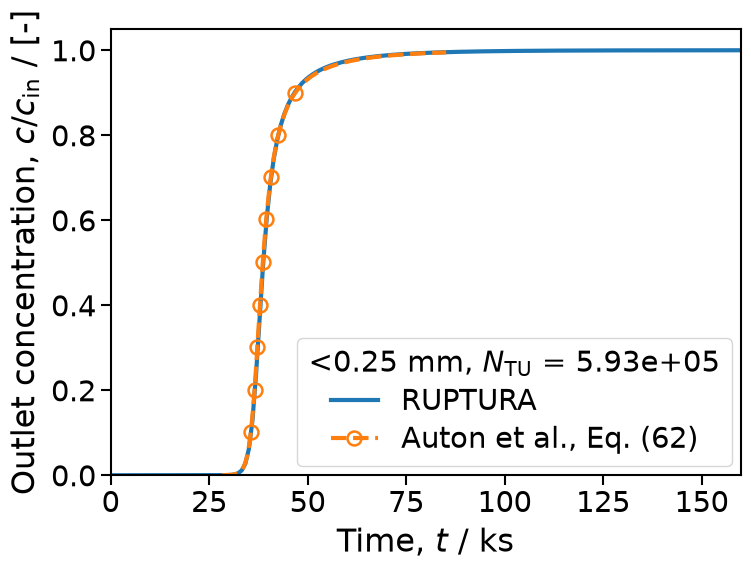

In [8]:
# Verification, R1p25e-4m: RUPTURA at L_fit without axial dispersion against Eq. (62) of Auton et al.
size = "R1p25e-4m"
time, C = outlet(run_directory(size))
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
ax.plot(time / 1e3, C, color="C0", label="RUPTURA")
ax.plot(eq62_time(levels, size) / 1e3, levels, linestyle="--", color="C1", marker="o", markerfacecolor="none",
        markevery=list(markers), label="Auton et al., Eq. (62)")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=f"{SIZES[size]['sieve']}, $N_\\mathrm{{TU}}$ = {SIZES[size]['beta']:.3g}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "verification_lt0p25mm.pdf")
plt.show()

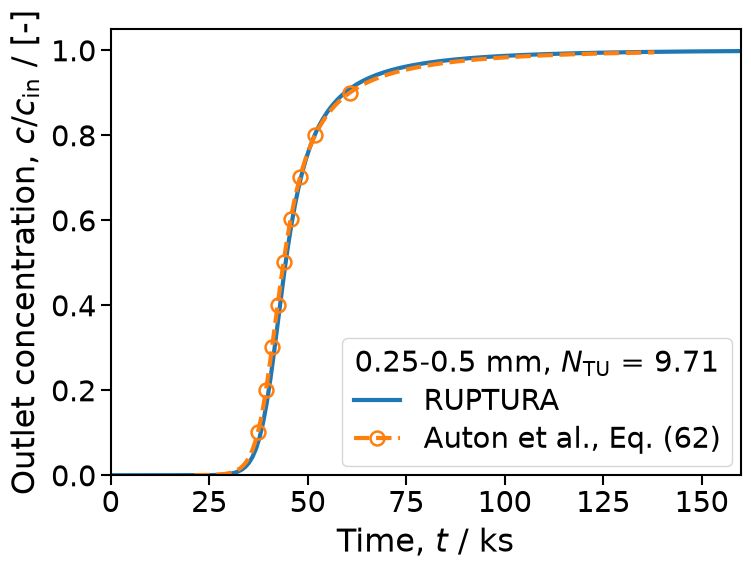

In [9]:
# Verification, R1p875e-4m: RUPTURA at L_fit without axial dispersion against Eq. (62) of Auton et al.
size = "R1p875e-4m"
time, C = outlet(run_directory(size))
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
ax.plot(time / 1e3, C, color="C0", label="RUPTURA")
ax.plot(eq62_time(levels, size) / 1e3, levels, linestyle="--", color="C1", marker="o", markerfacecolor="none",
        markevery=list(markers), label="Auton et al., Eq. (62)")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=f"{SIZES[size]['sieve']}, $N_\\mathrm{{TU}}$ = {SIZES[size]['beta']:.3g}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "verification_0p25-0p5mm.pdf")
plt.show()

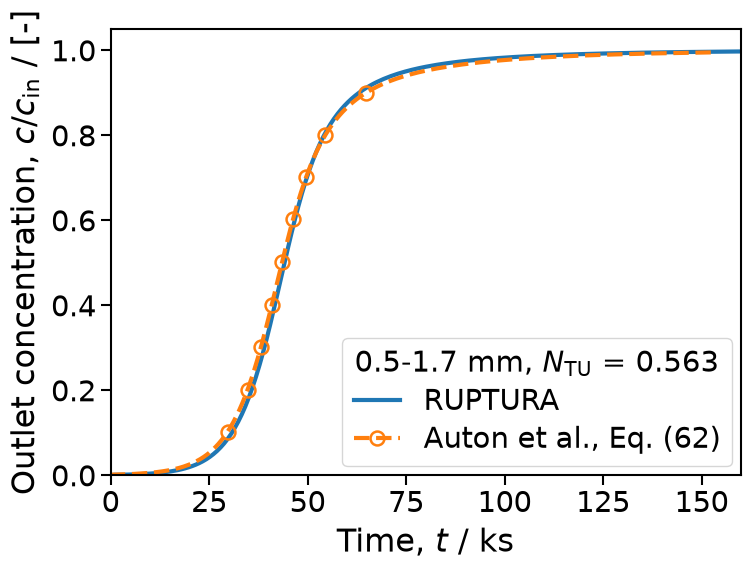

In [10]:
# Verification, R5p5e-4m: RUPTURA at L_fit without axial dispersion against Eq. (62) of Auton et al.
size = "R5p5e-4m"
time, C = outlet(run_directory(size))
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
ax.plot(time / 1e3, C, color="C0", label="RUPTURA")
ax.plot(eq62_time(levels, size) / 1e3, levels, linestyle="--", color="C1", marker="o", markerfacecolor="none",
        markevery=list(markers), label="Auton et al., Eq. (62)")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=f"{SIZES[size]['sieve']}, $N_\\mathrm{{TU}}$ = {SIZES[size]['beta']:.3g}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "verification_0p5-1p7mm.pdf")
plt.show()

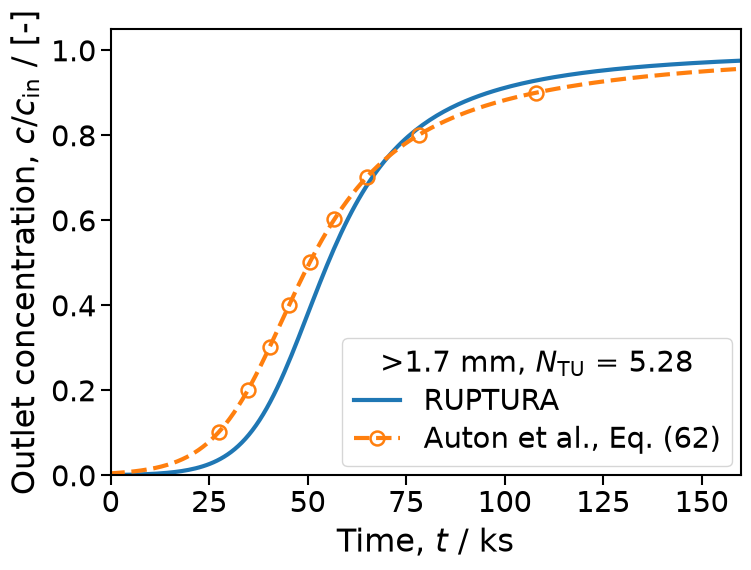

In [11]:
# Verification, R8p5e-4m: RUPTURA at L_fit without axial dispersion against Eq. (62) of Auton et al.
size = "R8p5e-4m"
time, C = outlet(run_directory(size))
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
ax.plot(time / 1e3, C, color="C0", label="RUPTURA")
ax.plot(eq62_time(levels, size) / 1e3, levels, linestyle="--", color="C1", marker="o", markerfacecolor="none",
        markevery=list(markers), label="Auton et al., Eq. (62)")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=f"{SIZES[size]['sieve']}, $N_\\mathrm{{TU}}$ = {SIZES[size]['beta']:.3g}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "verification_gt1p7mm.pdf")
plt.show()

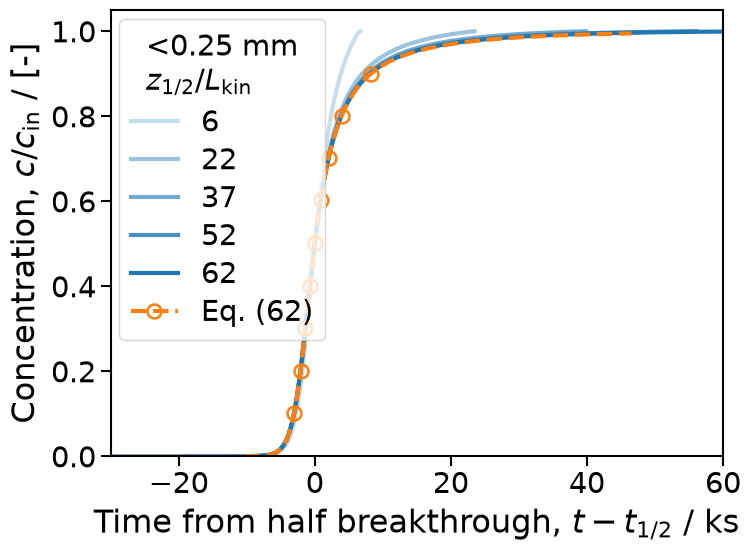

In [12]:
# Convergence to the travelling wave, R1p25e-4m: profiles in the column of 70 L_ref as t - t_1/2 = (z_1/2 - z)/w.
size = "R1p25e-4m"
profiles = wave_profiles(size)
shown = profiles[:: max(1, len(profiles) // 4)][:4] + profiles[-1:]
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
for k, (half, shift, C) in enumerate(shown):
    shade = 0.25 + 0.75 * k / max(1, len(shown) - 1)  # light to dark C0 as the front travels
    colour = (1.0 - shade) * np.ones(3) + shade * np.array(to_rgb("C0"))
    ax.plot(shift / 1e3, C, color=colour, label=f"{half / SIZES[size]['length_scale_m']:.0f}")
ax.plot((eq62_time(levels, size) - SIZES[size]["half_time_s"]) / 1e3, levels, linestyle="--", color="C1", marker="o",
        markerfacecolor="none", markevery=list(markers), label="Eq. (62)")
ax.set_xlim(-30.0, 60.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time from half breakthrough, $t - t_{1/2}$ / ks")
ax.set_ylabel("Concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="upper left", title=f"{SIZES[size]['sieve']}\n$z_{{1/2}}/L_\\mathrm{{kin}}$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "travelling_wave_lt0p25mm.pdf")
plt.show()

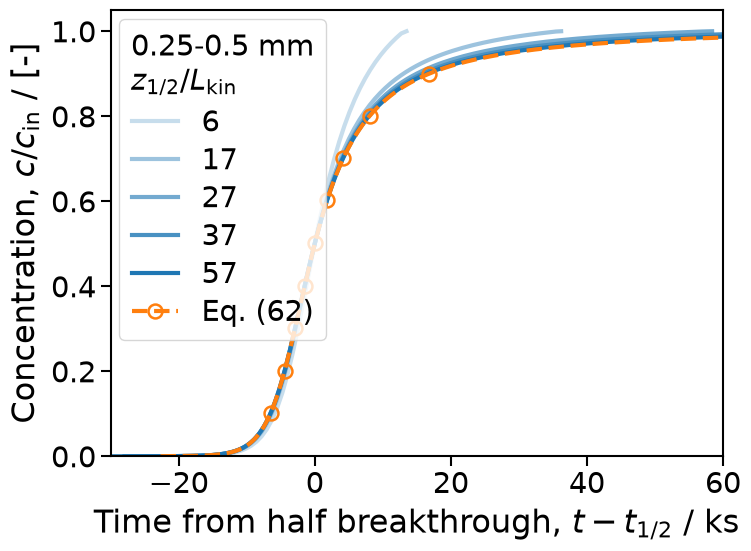

In [13]:
# Convergence to the travelling wave, R1p875e-4m: profiles in the column of 70 L_ref as t - t_1/2 = (z_1/2 - z)/w.
size = "R1p875e-4m"
profiles = wave_profiles(size)
shown = profiles[:: max(1, len(profiles) // 4)][:4] + profiles[-1:]
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
for k, (half, shift, C) in enumerate(shown):
    shade = 0.25 + 0.75 * k / max(1, len(shown) - 1)  # light to dark C0 as the front travels
    colour = (1.0 - shade) * np.ones(3) + shade * np.array(to_rgb("C0"))
    ax.plot(shift / 1e3, C, color=colour, label=f"{half / SIZES[size]['length_scale_m']:.0f}")
ax.plot((eq62_time(levels, size) - SIZES[size]["half_time_s"]) / 1e3, levels, linestyle="--", color="C1", marker="o",
        markerfacecolor="none", markevery=list(markers), label="Eq. (62)")
ax.set_xlim(-30.0, 60.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time from half breakthrough, $t - t_{1/2}$ / ks")
ax.set_ylabel("Concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="upper left", title=f"{SIZES[size]['sieve']}\n$z_{{1/2}}/L_\\mathrm{{kin}}$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "travelling_wave_0p25-0p5mm.pdf")
plt.show()

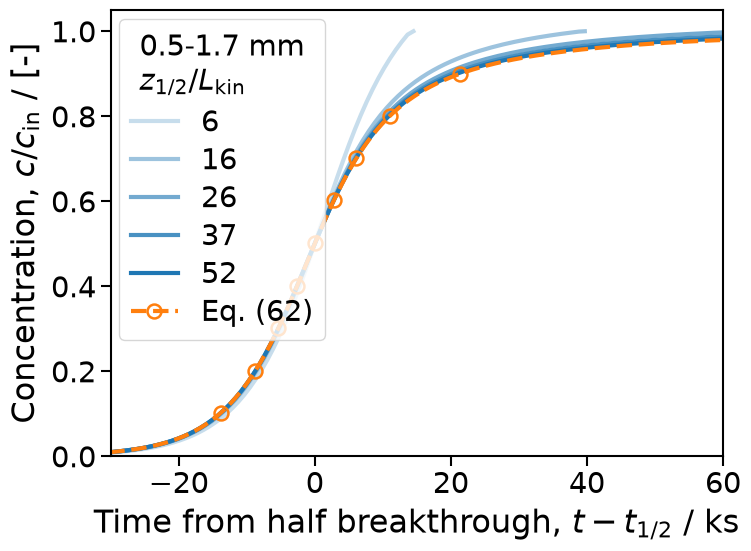

In [14]:
# Convergence to the travelling wave, R5p5e-4m: profiles in the column of 70 L_ref as t - t_1/2 = (z_1/2 - z)/w.
size = "R5p5e-4m"
profiles = wave_profiles(size)
shown = profiles[:: max(1, len(profiles) // 4)][:4] + profiles[-1:]
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
for k, (half, shift, C) in enumerate(shown):
    shade = 0.25 + 0.75 * k / max(1, len(shown) - 1)  # light to dark C0 as the front travels
    colour = (1.0 - shade) * np.ones(3) + shade * np.array(to_rgb("C0"))
    ax.plot(shift / 1e3, C, color=colour, label=f"{half / SIZES[size]['length_scale_m']:.0f}")
ax.plot((eq62_time(levels, size) - SIZES[size]["half_time_s"]) / 1e3, levels, linestyle="--", color="C1", marker="o",
        markerfacecolor="none", markevery=list(markers), label="Eq. (62)")
ax.set_xlim(-30.0, 60.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time from half breakthrough, $t - t_{1/2}$ / ks")
ax.set_ylabel("Concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="upper left", title=f"{SIZES[size]['sieve']}\n$z_{{1/2}}/L_\\mathrm{{kin}}$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "travelling_wave_0p5-1p7mm.pdf")
plt.show()

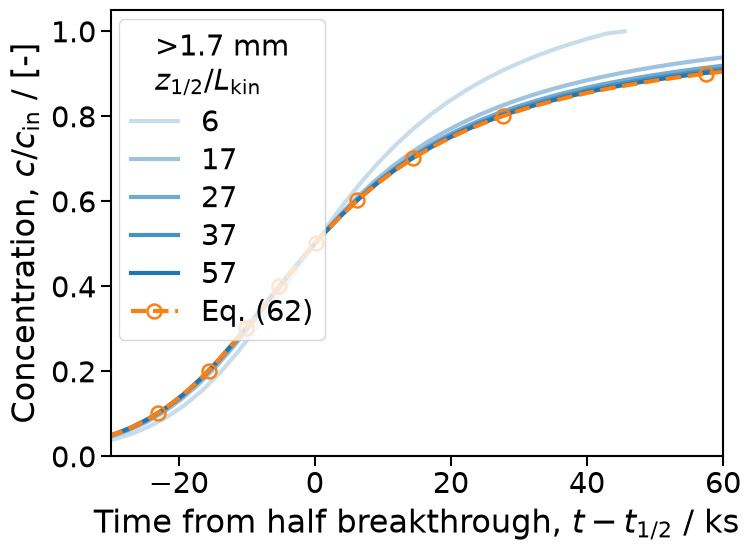

In [15]:
# Convergence to the travelling wave, R8p5e-4m: profiles in the column of 70 L_ref as t - t_1/2 = (z_1/2 - z)/w.
size = "R8p5e-4m"
profiles = wave_profiles(size)
shown = profiles[:: max(1, len(profiles) // 4)][:4] + profiles[-1:]
levels = np.concatenate((np.linspace(1e-4, 0.05, 50), np.linspace(0.05, 0.995, 400)))
markers = np.searchsorted(levels, np.arange(0.1, 1.0, 0.1))

fig, ax = plt.subplots()
for k, (half, shift, C) in enumerate(shown):
    shade = 0.25 + 0.75 * k / max(1, len(shown) - 1)  # light to dark C0 as the front travels
    colour = (1.0 - shade) * np.ones(3) + shade * np.array(to_rgb("C0"))
    ax.plot(shift / 1e3, C, color=colour, label=f"{half / SIZES[size]['length_scale_m']:.0f}")
ax.plot((eq62_time(levels, size) - SIZES[size]["half_time_s"]) / 1e3, levels, linestyle="--", color="C1", marker="o",
        markerfacecolor="none", markevery=list(markers), label="Eq. (62)")
ax.set_xlim(-30.0, 60.0)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel("Time from half breakthrough, $t - t_{1/2}$ / ks")
ax.set_ylabel("Concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="upper left", title=f"{SIZES[size]['sieve']}\n$z_{{1/2}}/L_\\mathrm{{kin}}$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "travelling_wave_gt1p7mm.pdf")
plt.show()

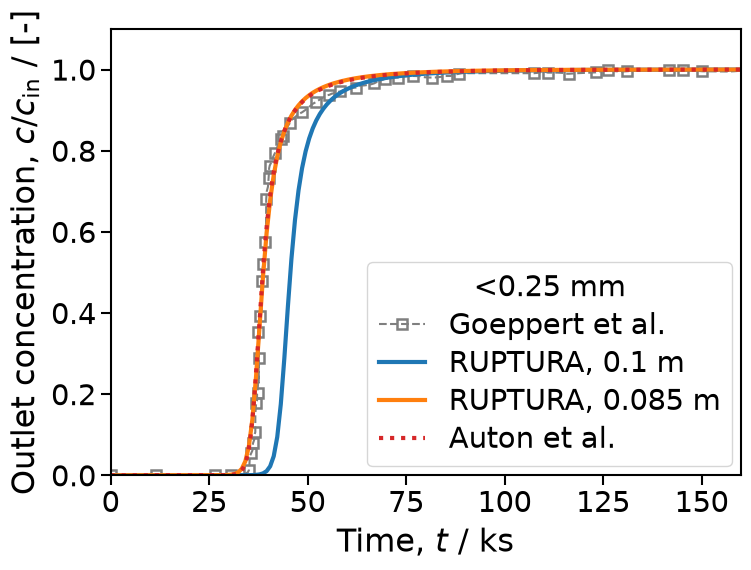

In [16]:
# Experiment, R1p25e-4m: data of Goeppert et al. against RUPTURA (Table 5 dispersion) and the fit of Auton et al.
size = "R1p25e-4m"
data_time, data_C = reference(size)
published_time, published_C = outlet(run_directory(size, column="published", dispersion="table5"))
fit_time, fit_C = outlet(run_directory(size, column="fit", dispersion="table5"))
time = np.linspace(0.0, 180.0e3, 2000)

fig, ax = plt.subplots()
ax.plot(data_time / 1e3, data_C, linestyle="--", linewidth=1.5, color="C7", marker="s", markerfacecolor="none",
        markersize=7, markevery=max(1, len(data_time) // 40), label="Goeppert et al.")
ax.plot(published_time / 1e3, published_C, color="C0", label="RUPTURA, 0.1 m")
ax.plot(fit_time / 1e3, fit_C, color="C1", label=f"RUPTURA, {SIZES[size]['fit_length_m']:.3f} m")
ax.plot(time / 1e3, eq62_outlet(time, size), color="C3", linestyle=":", label="Auton et al.")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=SIZES[size]["sieve"])
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experiment_lt0p25mm.pdf")
plt.show()

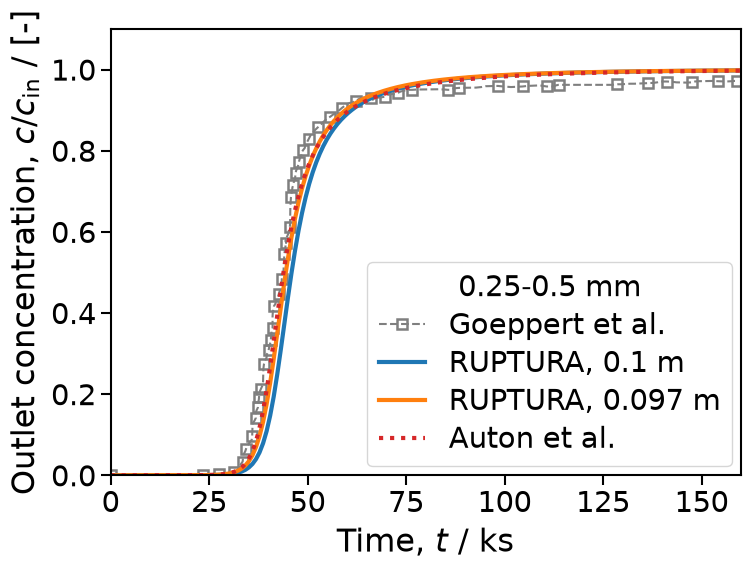

In [17]:
# Experiment, R1p875e-4m: data of Goeppert et al. against RUPTURA (Table 5 dispersion) and the fit of Auton et al.
size = "R1p875e-4m"
data_time, data_C = reference(size)
published_time, published_C = outlet(run_directory(size, column="published", dispersion="table5"))
fit_time, fit_C = outlet(run_directory(size, column="fit", dispersion="table5"))
time = np.linspace(0.0, 180.0e3, 2000)

fig, ax = plt.subplots()
ax.plot(data_time / 1e3, data_C, linestyle="--", linewidth=1.5, color="C7", marker="s", markerfacecolor="none",
        markersize=7, markevery=max(1, len(data_time) // 40), label="Goeppert et al.")
ax.plot(published_time / 1e3, published_C, color="C0", label="RUPTURA, 0.1 m")
ax.plot(fit_time / 1e3, fit_C, color="C1", label=f"RUPTURA, {SIZES[size]['fit_length_m']:.3f} m")
ax.plot(time / 1e3, eq62_outlet(time, size), color="C3", linestyle=":", label="Auton et al.")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=SIZES[size]["sieve"])
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experiment_0p25-0p5mm.pdf")
plt.show()

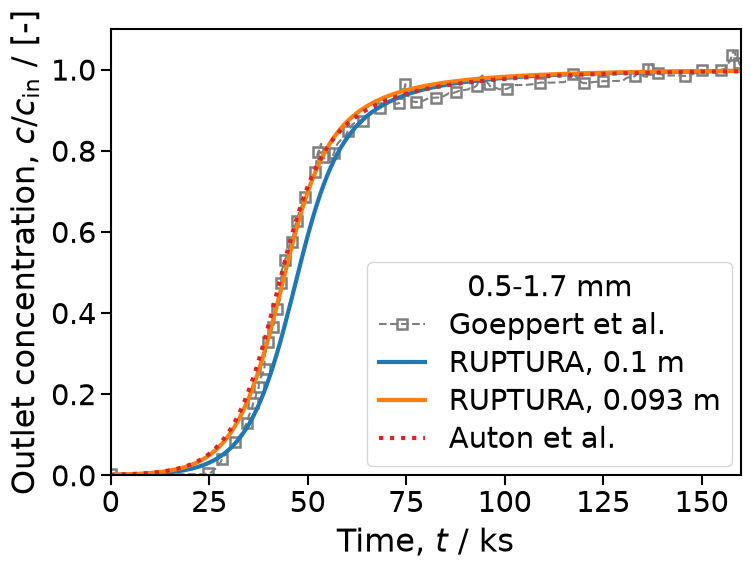

In [18]:
# Experiment, R5p5e-4m: data of Goeppert et al. against RUPTURA (Table 5 dispersion) and the fit of Auton et al.
size = "R5p5e-4m"
data_time, data_C = reference(size)
published_time, published_C = outlet(run_directory(size, column="published", dispersion="table5"))
fit_time, fit_C = outlet(run_directory(size, column="fit", dispersion="table5"))
time = np.linspace(0.0, 180.0e3, 2000)

fig, ax = plt.subplots()
ax.plot(data_time / 1e3, data_C, linestyle="--", linewidth=1.5, color="C7", marker="s", markerfacecolor="none",
        markersize=7, markevery=max(1, len(data_time) // 40), label="Goeppert et al.")
ax.plot(published_time / 1e3, published_C, color="C0", label="RUPTURA, 0.1 m")
ax.plot(fit_time / 1e3, fit_C, color="C1", label=f"RUPTURA, {SIZES[size]['fit_length_m']:.3f} m")
ax.plot(time / 1e3, eq62_outlet(time, size), color="C3", linestyle=":", label="Auton et al.")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=SIZES[size]["sieve"])
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experiment_0p5-1p7mm.pdf")
plt.show()

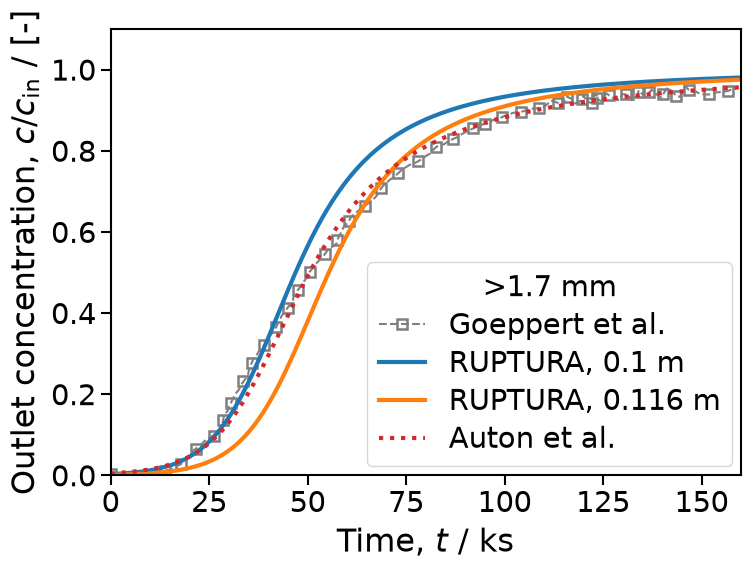

In [19]:
# Experiment, R8p5e-4m: data of Goeppert et al. against RUPTURA (Table 5 dispersion) and the fit of Auton et al.
size = "R8p5e-4m"
data_time, data_C = reference(size)
published_time, published_C = outlet(run_directory(size, column="published", dispersion="table5"))
fit_time, fit_C = outlet(run_directory(size, column="fit", dispersion="table5"))
time = np.linspace(0.0, 180.0e3, 2000)

fig, ax = plt.subplots()
ax.plot(data_time / 1e3, data_C, linestyle="--", linewidth=1.5, color="C7", marker="s", markerfacecolor="none",
        markersize=7, markevery=max(1, len(data_time) // 40), label="Goeppert et al.")
ax.plot(published_time / 1e3, published_C, color="C0", label="RUPTURA, 0.1 m")
ax.plot(fit_time / 1e3, fit_C, color="C1", label=f"RUPTURA, {SIZES[size]['fit_length_m']:.3f} m")
ax.plot(time / 1e3, eq62_outlet(time, size), color="C3", linestyle=":", label="Auton et al.")
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title=SIZES[size]["sieve"])
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experiment_gt1p7mm.pdf")
plt.show()

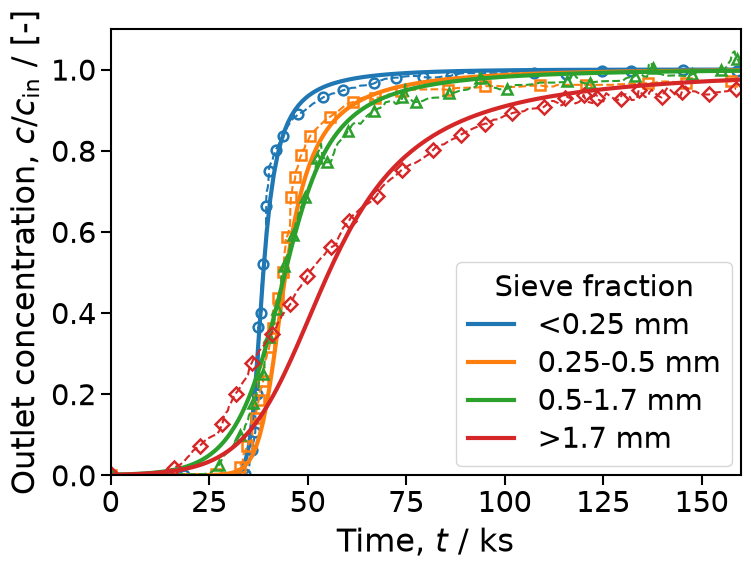

In [3]:
# Paper figure: the four sieve fractions in one panel, the data of Goeppert et al. against RUPTURA with the published
# parameters (Table 5 dispersion) in the column whose length holds the measured capacity.  The 0.1 m column and the
# travelling wave of Auton et al. are in the panels per size above (SI).
fig, ax = plt.subplots()
for color, marker, size in zip(("C0", "C1", "C2", "C3"), ("o", "s", "^", "D"), SIZES):
    data_time, data_C = reference(size)
    fit_time, fit_C = outlet(run_directory(size, column="fit", dispersion="table5"))
    ax.plot(data_time / 1e3, data_C, linestyle="--", linewidth=1.5, color=color, marker=marker, markerfacecolor="none",
            markersize=7, markevery=max(1, len(data_time) // 25))
    ax.plot(fit_time / 1e3, fit_C, color=color, label=SIZES[size]["sieve"])
ax.set_xlim(0.0, 160.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / ks")
ax.set_ylabel("Outlet concentration, $c/c_\\mathrm{in}$ / [-]")
ax.legend(loc="lower right", title="Sieve fraction")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experiment_all_sizes.pdf")
plt.show()


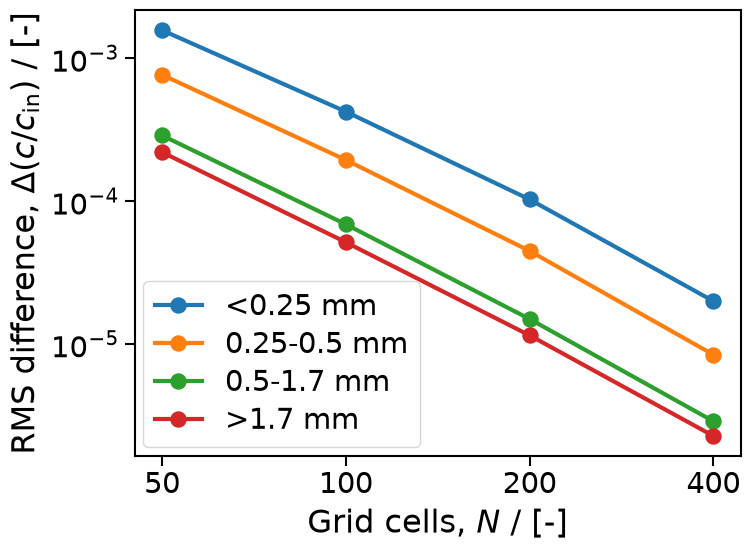

In [20]:
# Grid convergence: RMS difference of the outlet curve to 800 cells (L_fit, no dispersion).
fig, ax = plt.subplots()
for k, size in enumerate(SIZES):
    grids = [50, 100, 200, 400]
    rms = [difference(run_directory(size, grid_points=n), run_directory(size, grid_points=800))[0] for n in grids]
    ax.loglog(grids, rms, color=f"C{k}", marker="o", label=SIZES[size]["sieve"])
ax.set_xticks([50, 100, 200, 400], labels=["50", "100", "200", "400"])
ax.minorticks_off()
ax.set_xlabel("Grid cells, $N$ / [-]")
ax.set_ylabel("RMS difference, $\\Delta(c/c_\\mathrm{in})$ / [-]")  # to N = 800
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "grid_convergence.pdf")
plt.show()